# Tugas Hands-On 3: Pandas Lanjutan
## Kasus 01: Credit Risk Prediction (Fintech)

**Tujuan:** mengaudit dan membersihkan data kredit, menganalisis faktor risiko gagal bayar, lalu menyiapkan data untuk model **tanpa data leakage**.

**Cara menjalankan (Google Colab):** klik *Runtime → Run all*. Saat sel pertama berjalan, unggah file `case1_credit_risk.csv` jika diminta. Untuk pengecekan akhir gunakan *Runtime → Restart session and run all*.

| Item | Keterangan |
| --- | --- |
| Dataset | `case1_credit_risk.csv` (2.500 baris × 15 kolom) |
| Target | `status_kredit` (`Default` / `Tidak Default`) |
| Kunci | `customer_id` |
| Jenis tugas | Klasifikasi biner |

## Tahap 1: Muat data

In [55]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (10, 4)
pd.options.display.float_format = '{:,.3f}'.format

os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)

PATH = 'data/case1_credit_risk.csv'

# Jika file belum ada, minta unggah (Colab). Di Jupyter lokal, taruh file di folder data/.
if not os.path.exists(PATH):
    try:
        from google.colab import files
        print('Unggah file case1_credit_risk.csv ...')
        unggahan = files.upload()
        os.replace(list(unggahan)[0], PATH)
    except ImportError:
        raise FileNotFoundError(f'Letakkan dataset di {PATH}')

df_mentah = pd.read_csv(PATH)   # data mentah: TIDAK diubah, semua perubahan lewat salinan

TARGET     = 'status_kredit'
KUNCI      = 'customer_id'
GRUP       = 'tujuan_pinjaman'   # grup untuk deteksi outlier per grup
KOLOM_NUM  = 'credit_score'      # kolom numerik utama untuk laporan kualitas

print('Shape:', df_mentah.shape)

Shape: (2500, 15)


In [56]:
df_mentah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2500 non-null   object 
 1   usia                    2445 non-null   float64
 2   jenis_kelamin           2426 non-null   object 
 3   pendidikan              2423 non-null   object 
 4   status_pekerjaan        2415 non-null   object 
 5   pendapatan_tahunan_idr  2441 non-null   float64
 6   jumlah_pinjaman_idr     2500 non-null   int64  
 7   tenor_bulan             2500 non-null   int64  
 8   tujuan_pinjaman         2500 non-null   object 
 9   credit_score            2424 non-null   float64
 10  jumlah_pinjaman_aktif   2500 non-null   int64  
 11  rasio_utang_pendapatan  2390 non-null   float64
 12  riwayat_telat_bayar     2426 non-null   float64
 13  nilai_agunan_idr        2138 non-null   float64
 14  status_kredit           2500 non-null   

In [57]:
df_mentah.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,2500,2500,CUST000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
usia,"2,445.000",NaN,NaN,NaN,44.059,12.844,22.000,33.000,44.000,55.000,65.000
jenis_kelamin,2426,8,Perempuan,1206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pendidikan,2423,4,SMA,630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_pekerjaan,2415,5,PNS,495,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pendapatan_tahunan_idr,"2,441.000",NaN,NaN,NaN,"26,910,460.272","13,512,611.108","3,035,415.000","15,233,921.000","27,098,275.000","38,573,176.000","49,918,461.000"
jumlah_pinjaman_idr,"2,500.000",NaN,NaN,NaN,"152,233,181.972","83,899,657.892","5,045,620.000","80,202,180.250","152,049,789.000","224,038,246.500","299,939,026.000"
tenor_bulan,"2,500.000",NaN,NaN,NaN,35.222,17.246,12.000,24.000,36.000,48.000,60.000
tujuan_pinjaman,2500,5,Renovasi Rumah,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_score,"2,424.000",NaN,NaN,NaN,577.921,163.194,-699.000,448.000,577.000,718.250,850.000


In [58]:
df_mentah.head()

,customer_id,usia,jenis_kelamin,pendidikan,status_pekerjaan,pendapatan_tahunan_idr,jumlah_pinjaman_idr,tenor_bulan,tujuan_pinjaman,credit_score,jumlah_pinjaman_aktif,rasio_utang_pendapatan,riwayat_telat_bayar,nilai_agunan_idr,status_kredit
0,CUST000001,28.000,Laki-laki,SMA,NaN,"14,628,940.000",278922013,12,Modal Usaha,384.000,1,0.600,7.000,"14,293,345.000",Default
1,CUST000002,24.000,Laki-laki,S1,Freelancer,"37,878,659.000",154124154,48,Kendaraan,707.000,1,0.830,5.000,"441,515,215.000",Tidak Default
2,CUST000003,23.000,Laki-laki,S1,Wiraswasta,"33,633,748.000",162988556,36,Konsumsi,840.000,4,0.430,12.000,"78,803,799.000",Tidak Default
3,CUST000004,59.000,Laki-laki,S2,Freelancer,"45,851,485.000",18154653,60,Kendaraan,NaN,3,0.510,9.000,NaN,Tidak Default
4,CUST000005,59.000,Laki-laki,D3,Wiraswasta,NaN,78274484,36,Renovasi Rumah,511.000,1,0.220,2.000,"211,908,435.000",Tidak Default


**Catatan awal dari `info()` dan `describe()`:**
- 9 dari 15 kolom punya nilai kosong; `nilai_agunan_idr` paling banyak (± 14%).
- `jenis_kelamin` punya 8 nilai unik padahal seharusnya 2 (ada variasi huruf besar/kecil dan simbol `@`).
- `credit_score` punya nilai minimum negatif, padahal skala skor kredit adalah 300–850.
- Tidak ada kolom tanggal, sehingga analisis time series tidak berlaku (dijelaskan di Tahap 3).

## Tahap 2: Audit kualitas dan pembersihan

Urutan pembersihan sesuai aturan: **duplikat → missing value → outlier → tipe data**.

### 2.1 Fungsi `cek_kualitas`

Sama seperti kerangka di soal, hanya ditambah `astype('float64')` agar aman dipakai pada kolom bertipe `Int64` (nullable integer) setelah tipe data dirapikan.

In [59]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    x   = d[kolom_num].astype('float64')
    g   = x.groupby(d[kolom_grup], observed=True)
    q1  = g.transform(lambda s: s.quantile(0.25))
    q3  = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

### 2.2 Audit awal (apa saja masalahnya?)

In [60]:
# a. Duplikat
print('Duplikat berdasarkan customer_id :', df_mentah.duplicated(subset=KUNCI).sum())
print('Duplikat seluruh isi (tanpa ID)  :', df_mentah.duplicated(subset=df_mentah.columns.drop(KUNCI)).sum())

# b. Missing value per kolom
mv = pd.DataFrame({'n_missing': df_mentah.isnull().sum(),
                   'persen': df_mentah.isnull().mean() * 100})
mv[mv.n_missing > 0].sort_values('n_missing', ascending=False)

Duplikat berdasarkan customer_id : 0
Duplikat seluruh isi (tanpa ID)  : 0


,n_missing,persen
nilai_agunan_idr,362,14.480
rasio_utang_pendapatan,110,4.400
status_pekerjaan,85,3.400
pendidikan,77,3.080
credit_score,76,3.040
riwayat_telat_bayar,74,2.960
jenis_kelamin,74,2.960
pendapatan_tahunan_idr,59,2.360
usia,55,2.200


In [61]:
# c. Konsistensi kategori
print(df_mentah['jenis_kelamin'].value_counts(dropna=False))

jenis_kelamin
Perempuan    1206
Laki-laki    1186
NaN            74
L@ki-l@ki       8
Perempu@n       8
laki-laki       6
perempuan       5
PEREMPUAN       4
LAKI-LAKI       3
Name: count, dtype: int64


In [62]:
# d. Nilai di luar domain
print('credit_score di luar 300-850:')
print(df_mentah.loc[~df_mentah['credit_score'].between(300, 850) & df_mentah['credit_score'].notna(),
                    [KUNCI, 'credit_score']])

credit_score di luar 300-850:
     customer_id  credit_score
1752  CUST001753      -444.000
2100  CUST002101      -699.000
2268  CUST002269      -606.000


In [63]:
# e. Outlier IQR per grup (tujuan_pinjaman) untuk semua kolom numerik kontinu
kolom_kontinu = ['pendapatan_tahunan_idr', 'jumlah_pinjaman_idr', 'credit_score',
                 'rasio_utang_pendapatan', 'nilai_agunan_idr']
pd.Series({c: cek_kualitas(df_mentah, c, GRUP, KUNCI)['n_outlier'] for c in kolom_kontinu},
          name='n_outlier_IQR_per_grup')

,n_outlier_IQR_per_grup
pendapatan_tahunan_idr,0
jumlah_pinjaman_idr,0
credit_score,3
rasio_utang_pendapatan,0
nilai_agunan_idr,0


**Temuan audit**
1. Tidak ada baris duplikat (ID unik, isi tidak ada yang kembar).
2. Missing value ada di 9 kolom. Numerik: `usia`, `pendapatan_tahunan_idr`, `credit_score`, `rasio_utang_pendapatan`, `riwayat_telat_bayar`, `nilai_agunan_idr`. Kategorikal: `jenis_kelamin`, `pendidikan`, `status_pekerjaan`. Kolom target dan kunci lengkap.
3. `jenis_kelamin` tidak konsisten: huruf besar/kecil berbeda dan ada simbol `@` (`L@ki-l@ki`, `Perempu@n`).
4. `credit_score` berisi tiga nilai negatif yang mustahil. Inilah satu-satunya outlier nyata; kolom numerik lain tidak punya outlier IQR per grup.

### 2.3 Pembersihan lewat kode

Keputusan dan alasannya tertulis di komentar tiap langkah.

In [64]:
df = df_mentah.copy()
log = []   # catatan perubahan untuk dilaporkan

# ---------- 1. DUPLIKAT ----------
# Duplikat didefinisikan berdasarkan kunci (customer_id): satu pelanggan = satu baris.
n0 = len(df)
df = df.drop_duplicates(subset=KUNCI, keep='first')
log.append(f'Duplikat dibuang: {n0 - len(df)} baris')

# ---------- 2. MISSING VALUE ----------
# Prinsip: imputasi yang BELAJAR dari data (median/modus) ditunda ke pipeline setelah split,
# agar tidak leakage. Yang dilakukan di sini hanya aturan tetap yang tidak menghitung statistik data.

# 2a. Baris tanpa target tidak bisa dipakai untuk melatih/menguji model -> dibuang.
n0 = len(df)
df = df.dropna(subset=[TARGET])
log.append(f'Baris tanpa target dibuang: {n0 - len(df)}')

# 2b. Kolom yang hampir kosong (> 50% missing) tidak informatif -> dibuang.
kolom_kosong = df.columns[df.isnull().mean() > 0.5].tolist()
df = df.drop(columns=kolom_kosong)
log.append(f'Kolom > 50% kosong dibuang: {kolom_kosong}')

# 2c. Kategorikal kosong -> kategori tetap 'Tidak Diketahui' (konstanta, bukan statistik data).
kolom_kat = ['jenis_kelamin', 'pendidikan', 'status_pekerjaan']
df[kolom_kat] = df[kolom_kat].fillna('Tidak Diketahui')
log.append(f'Kategorikal kosong diisi "Tidak Diketahui": {kolom_kat}')

# 2d. Kolom numerik dengan missing > 5% diberi penanda (flag), karena kekosongan bisa
#     bermakna (mis. tidak ada agunan). Nilainya sendiri diimputasi nanti setelah split.
for c in ['pendapatan_tahunan_idr', 'credit_score', 'rasio_utang_pendapatan',
          'riwayat_telat_bayar', 'nilai_agunan_idr', 'usia']:
    if df[c].isnull().mean() > 0.05:
        df[f'{c}_kosong'] = df[c].isnull().astype(int)
        log.append(f'Flag missing ditambahkan: {c}_kosong')

# ---------- 3. OUTLIER ----------
# 3a. Nilai di luar domain (credit_score harus 300-850) dianggap data rusak -> NaN.
#     Tidak di-clip ke 300, karena itu mengarang nilai; biarkan diimputasi di pipeline.
rusak = ~df['credit_score'].between(300, 850) & df['credit_score'].notna()
log.append(f'credit_score di luar 300-850 diubah jadi NaN: {rusak.sum()} baris')
df.loc[rusak, 'credit_score'] = np.nan

# 3b. Outlier IQR per grup pada kolom kontinu lain -> clip ke batas IQR (winsorizing),
#     supaya baris tetap dipertahankan. (Hasil audit: tidak ada, jadi tidak mengubah apa pun.)
def clip_iqr(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return s.clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

for c in ['pendapatan_tahunan_idr', 'jumlah_pinjaman_idr', 'rasio_utang_pendapatan', 'nilai_agunan_idr']:
    sebelum = df[c].copy()
    df[c] = df.groupby(GRUP)[c].transform(clip_iqr)
    n_ubah = (sebelum.notna() & (sebelum != df[c])).sum()   # abaikan NaN
    if n_ubah:
        log.append(f'{c}: {n_ubah} nilai di-clip (IQR per {GRUP})')

# ---------- 4. TIPE DATA & KONSISTENSI ----------
# 4a. Rapikan teks: strip spasi pada semua kolom teks.
kolom_teks = df.select_dtypes(exclude='number').columns
for c in kolom_teks:
    df[c] = df[c].astype(str).str.strip()

# 4b. jenis_kelamin: samakan huruf besar/kecil dan ganti simbol '@' menjadi 'a'.
df['jenis_kelamin'] = (df['jenis_kelamin'].str.replace('@', 'a', regex=False).str.lower()
                       .replace({'laki-laki': 'Laki-laki', 'perempuan': 'Perempuan',
                                 'tidak diketahui': 'Tidak Diketahui'}))
log.append('jenis_kelamin dinormalkan menjadi Laki-laki / Perempuan / Tidak Diketahui')

# 4c. Kolom bilangan bulat yang nilainya mengandung NaN -> Int64 (nullable integer).
for c in ['usia', 'credit_score', 'riwayat_telat_bayar']:
    df[c] = df[c].round().astype('Int64')

# 4d. Kolom kategorikal -> category.
for c in ['jenis_kelamin', 'pendidikan', 'status_pekerjaan', 'tujuan_pinjaman', TARGET]:
    df[c] = df[c].astype('category')

print('\n'.join('- ' + l for l in log))
print('\nShape setelah pembersihan:', df.shape)

- Duplikat dibuang: 0 baris
- Baris tanpa target dibuang: 0
- Kolom > 50% kosong dibuang: []
- Kategorikal kosong diisi "Tidak Diketahui": ['jenis_kelamin', 'pendidikan', 'status_pekerjaan']
- Flag missing ditambahkan: nilai_agunan_idr_kosong
- credit_score di luar 300-850 diubah jadi NaN: 3 baris
- jenis_kelamin dinormalkan menjadi Laki-laki / Perempuan / Tidak Diketahui

Shape setelah pembersihan: (2500, 16)


### 2.4 Laporan kualitas: sebelum vs sesudah

In [65]:
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, KOLOM_NUM, GRUP, KUNCI),
    'sesudah': cek_kualitas(df,        KOLOM_NUM, GRUP, KUNCI),
})
laporan.to_csv('laporan_kualitas.csv')
laporan

,sebelum,sesudah
n_baris,2500,2500
n_duplikat,0,0
n_missing,972,739
n_outlier,3,0


In [66]:
# Rincian missing per kolom, sebelum vs sesudah
rincian = pd.DataFrame({
    'missing_sebelum': df_mentah.isnull().sum(),
    'missing_sesudah': df.isnull().sum().reindex(df_mentah.columns),
})
rincian[(rincian.missing_sebelum > 0) | (rincian.missing_sesudah > 0)]

,missing_sebelum,missing_sesudah
usia,55,55
jenis_kelamin,74,0
pendidikan,77,0
status_pekerjaan,85,0
pendapatan_tahunan_idr,59,59
credit_score,76,79
rasio_utang_pendapatan,110,110
riwayat_telat_bayar,74,74
nilai_agunan_idr,362,362


In [67]:
print(df['jenis_kelamin'].value_counts())
print()
print(df.dtypes)

jenis_kelamin
Perempuan          1223
Laki-laki          1203
Tidak Diketahui      74
Name: count, dtype: int64

customer_id                  object
usia                          Int64
jenis_kelamin              category
pendidikan                 category
status_pekerjaan           category
pendapatan_tahunan_idr      float64
jumlah_pinjaman_idr           int64
tenor_bulan                   int64
tujuan_pinjaman            category
credit_score                  Int64
jumlah_pinjaman_aktif         int64
rasio_utang_pendapatan      float64
riwayat_telat_bayar           Int64
nilai_agunan_idr            float64
status_kredit              category
nilai_agunan_idr_kosong       int64
dtype: object


**Interpretasi tabel kualitas**

- `n_duplikat` tetap 0: memang tidak ada duplikat.
- `n_outlier` turun dari 3 ke 0: tiga skor kredit negatif (tidak valid) sudah dihapus dari kolom `credit_score`.
- `n_missing` **tidak** turun ke nol, dan ini disengaja. Kolom kategorikal sudah terisi `Tidak Diketahui` (turun), tetapi kolom numerik masih memiliki NaN. Tiga skor negatif malah menambah NaN pada `credit_score`. Mengisi median/modus sebelum split akan membuat statistik data uji ikut menentukan nilai pengisi (leakage), sehingga imputasi dilakukan di `ColumnTransformer` pada Tahap 4, yang hanya di-`fit` pada data train.
- Jumlah baris tetap 2.500 karena tidak ada baris yang perlu dibuang.

## Tahap 3: Analisis

Analisis disesuaikan dengan data:

- **Time series dilewati**: tidak ada kolom tanggal pada dataset ini.
- **RFM dilewati**: RFM butuh riwayat transaksi per pelanggan (recency, frequency, monetary). Dataset ini satu baris per pelanggan dengan satu pengajuan pinjaman.
- **Dipakai**: `groupby` lanjutan, binning kuantil, tabel silang (pivot), dan korelasi, dengan fokus pada tingkat gagal bayar (*default rate*).

In [68]:
# Target numerik untuk analisis (1 = Default)
df['default'] = (df[TARGET] == 'Default').astype(int)

print('Proporsi kelas target:')
print(df[TARGET].value_counts(normalize=True).round(3))

Proporsi kelas target:
status_kredit
Tidak Default   0.566
Default         0.434
Name: proportion, dtype: float64


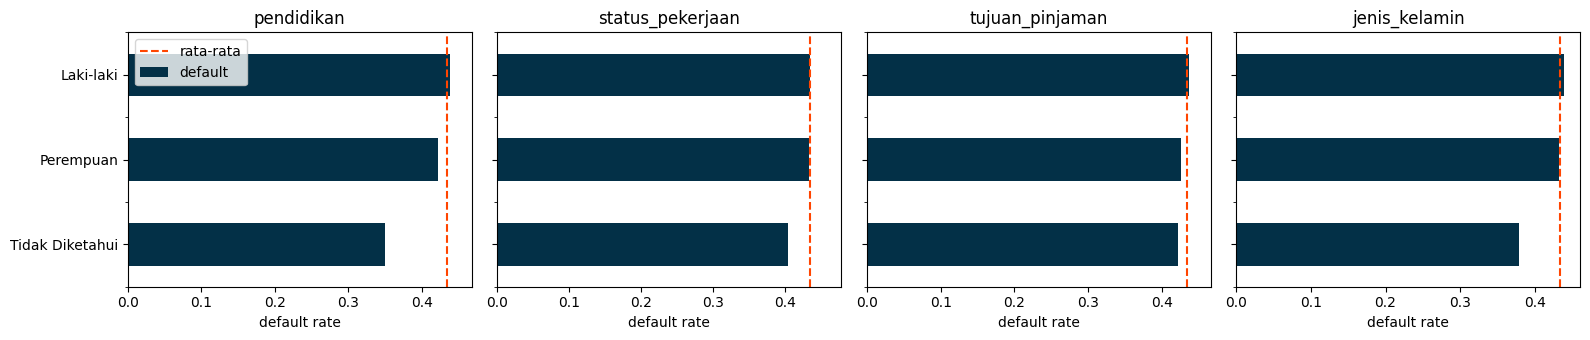

In [69]:
# Tingkat default per segmen kategorikal
kolom_seg = ['pendidikan', 'status_pekerjaan', 'tujuan_pinjaman', 'jenis_kelamin']
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, c in zip(axes, kolom_seg):
    t = df.groupby(c, observed=True)['default'].mean().sort_values()
    t.plot(kind='barh', ax=ax, color='#033047')
    ax.axvline(df['default'].mean(), color='#FF4500', ls='--', label='rata-rata')
    ax.set_title(c); ax.set_xlabel('default rate'); ax.set_ylabel('')
axes[0].legend()
plt.tight_layout(); plt.show()

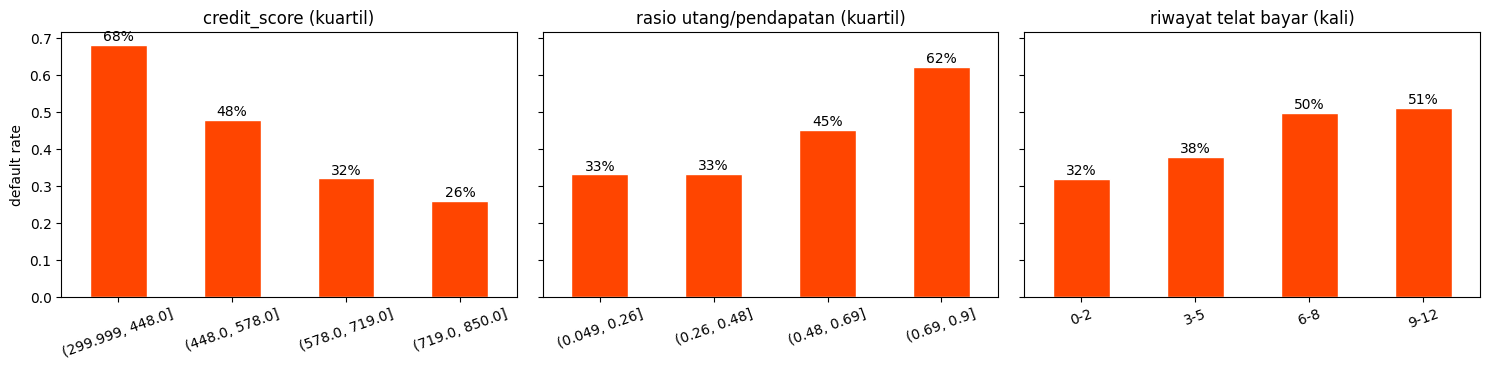

                  mean  count
bin_score                    
(299.999, 448.0] 0.682    606
(448.0, 578.0]   0.479    609
(578.0, 719.0]   0.321    604
(719.0, 850.0]   0.261    602
               mean  count
bin_dti                   
(0.049, 0.26] 0.332    605
(0.26, 0.48]  0.334    596
(0.48, 0.69]  0.453    616
(0.69, 0.9]   0.623    573
           mean  count
bin_telat             
0-2       0.320    547
3-5       0.379    546
6-8       0.498    568
9-12      0.511    765


In [70]:
# Tingkat default per kuartil credit_score, rasio utang, dan per jumlah keterlambatan
df['bin_score'] = pd.qcut(df['credit_score'].astype(float), 4, duplicates='drop')
df['bin_dti']   = pd.qcut(df['rasio_utang_pendapatan'], 4, duplicates='drop')
df['bin_telat'] = pd.cut(df['riwayat_telat_bayar'].astype(float), [-1, 2, 5, 8, 12],
                         labels=['0-2', '3-5', '6-8', '9-12'])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (c, judul) in zip(axes, [('bin_score', 'credit_score (kuartil)'),
                                 ('bin_dti', 'rasio utang/pendapatan (kuartil)'),
                                 ('bin_telat', 'riwayat telat bayar (kali)')]):
    t = df.groupby(c, observed=True)['default'].mean()
    t.plot(kind='bar', ax=ax, color='#FF4500', edgecolor='white')
    ax.set_title(judul); ax.set_xlabel(''); ax.set_ylabel('default rate'); ax.tick_params(axis='x', rotation=20)
    for i, v in enumerate(t.values):
        ax.text(i, v + .01, f'{v:.0%}', ha='center')
plt.tight_layout(); plt.show()

print(df.groupby('bin_score', observed=True)['default'].agg(['mean', 'count']).round(3))
print(df.groupby('bin_dti', observed=True)['default'].agg(['mean', 'count']).round(3))
print(df.groupby('bin_telat', observed=True)['default'].agg(['mean', 'count']).round(3))

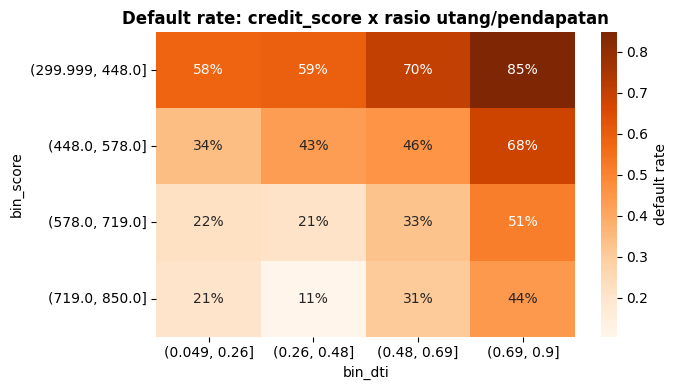

In [71]:
# Tabel silang: credit_score x rasio utang -> default rate
pivot = pd.pivot_table(df, values='default', index='bin_score', columns='bin_dti',
                       aggfunc='mean', observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt='.0%', cmap='Oranges', cbar_kws={'label': 'default rate'})
plt.title('Default rate: credit_score x rasio utang/pendapatan', fontweight='bold')
plt.tight_layout(); plt.show()

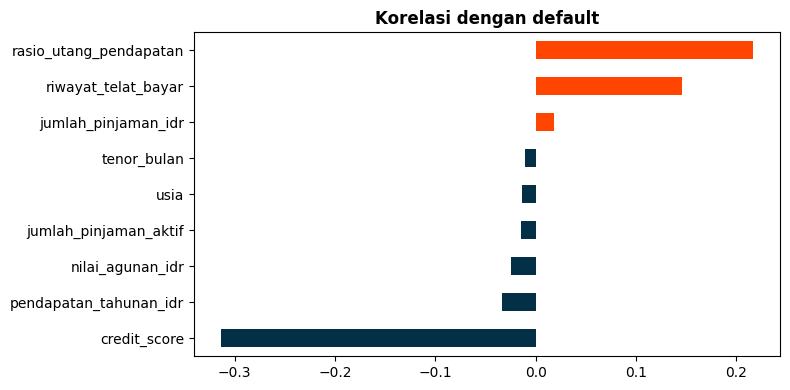

,default
credit_score,-0.314
pendapatan_tahunan_idr,-0.034
nilai_agunan_idr,-0.024
jumlah_pinjaman_aktif,-0.015
usia,-0.013
tenor_bulan,-0.011
jumlah_pinjaman_idr,0.018
riwayat_telat_bayar,0.146
rasio_utang_pendapatan,0.217


In [72]:
# Korelasi fitur numerik terhadap default
num = ['usia', 'pendapatan_tahunan_idr', 'jumlah_pinjaman_idr', 'tenor_bulan', 'credit_score',
       'jumlah_pinjaman_aktif', 'rasio_utang_pendapatan', 'riwayat_telat_bayar', 'nilai_agunan_idr']
korelasi = df[num + ['default']].astype(float).corr()['default'].drop('default').sort_values()
korelasi.plot(kind='barh', color=['#FF4500' if v > 0 else '#033047' for v in korelasi], figsize=(8, 4))
plt.title('Korelasi dengan default', fontweight='bold'); plt.tight_layout(); plt.show()
korelasi.round(3)

In [73]:
# Angka-angka untuk tiga temuan
rata = df['default'].mean()
skor = df.groupby('bin_score', observed=True)['default'].mean()
dti  = df.groupby('bin_dti', observed=True)['default'].mean()
tlt  = df.groupby('bin_telat', observed=True)['default'].mean()
risiko_tinggi = df[(df['credit_score'] < df['credit_score'].quantile(.25)) &
                   (df['rasio_utang_pendapatan'] > df['rasio_utang_pendapatan'].quantile(.75))]
print(f'Rata-rata default                  : {rata:.1%}')
print(f'Default skor terendah vs tertinggi : {skor.iloc[0]:.1%} vs {skor.iloc[-1]:.1%}')
print(f'Default DTI terendah vs tertinggi  : {dti.iloc[0]:.1%} vs {dti.iloc[-1]:.1%}')
print(f'Default telat 0-2 vs 9-12 kali     : {tlt.iloc[0]:.1%} vs {tlt.iloc[-1]:.1%}')
print(f'Segmen skor terendah & DTI tertinggi: {len(risiko_tinggi)} orang, default {risiko_tinggi["default"].mean():.1%}')
sel = df[df['pendidikan'] != 'Tidak Diketahui'].groupby('pendidikan', observed=True)['default'].mean()
print(f'Selisih default rate antar tingkat pendidikan (yang diketahui): {(sel.max() - sel.min()) * 100:.1f} poin persentase')

Rata-rata default                  : 43.4%
Default skor terendah vs tertinggi : 68.2% vs 26.1%
Default DTI terendah vs tertinggi  : 33.2% vs 62.3%
Default telat 0-2 vs 9-12 kali     : 32.0% vs 51.1%
Segmen skor terendah & DTI tertinggi: 141 orang, default 85.1%
Selisih default rate antar tingkat pendidikan (yang diketahui): 2.4 poin persentase


### Tiga temuan yang bisa ditindaklanjuti

1. **Skor kredit adalah pemisah risiko terkuat.** Tingkat gagal bayar pada kuartil skor terendah (≤ 448) adalah **68,2%**, sedangkan pada kuartil tertinggi (> 719) hanya **26,1%** (rata-rata keseluruhan 43,4%). *Tindak lanjut:* jadikan skor < 450 sebagai pemicu tinjauan manual atau plafon pinjaman yang lebih rendah.
2. **Rasio utang/pendapatan di atas 0,69 melipatgandakan risiko, dan efeknya menumpuk dengan skor rendah.** Default 62,3% pada kuartil DTI tertinggi versus 33,2% pada kuartil terendah. Kelompok dengan skor terendah **dan** DTI tertinggi (141 pelanggan, ± 5,6% data) gagal bayar **85,1%**. *Tindak lanjut:* terapkan batas DTI maksimum sekitar 0,69 dan tolak otomatis atau minta jaminan tambahan untuk kombinasi skor rendah + DTI tinggi.
3. **Perilaku bayar lebih menentukan daripada profil demografis.** Pelanggan dengan ≥ 6 keterlambatan gagal bayar sekitar 50%, versus 32,0% untuk 0–2 keterlambatan. Sebaliknya, tingkat pendidikan, status pekerjaan, dan tujuan pinjaman hanya berselisih beberapa poin persentase (pendidikan 2,4 poin). *Tindak lanjut:* jangan jadikan pendidikan atau tujuan pinjaman dasar kebijakan risiko; fokuskan penilaian pada riwayat keterlambatan, skor, dan DTI.

## Tahap 4: Persiapan model tanpa leakage

Urutan: **split dulu** → imputasi, scaling, encoding di dalam `ColumnTransformer` yang hanya di-`fit` pada data train.

In [74]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Fitur: buang target, kunci, dan kolom bantu analisis (default, bin_*) agar tidak bocor.
kolom_bantu = ['default', 'bin_score', 'bin_dti', 'bin_telat']
X = df.drop(columns=[TARGET, KUNCI] + kolom_bantu).copy()
y = (df[TARGET] == 'Default').astype(int)

kolom_kat = X.select_dtypes(exclude='number').columns.tolist()
for c in kolom_kat:
    X[c] = X[c].astype(str)                   # category -> teks untuk OneHotEncoder
kolom_num = [c for c in X.columns if c not in kolom_kat and not c.endswith('_kosong')]
kolom_flag = [c for c in X.columns if c.endswith('_kosong')]
X[kolom_num] = X[kolom_num].astype('float64') # Int64 -> float agar imputer aman

print('Numerik   :', kolom_num)
print('Flag 0/1  :', kolom_flag)
print('Kategorik :', kolom_kat)

Numerik   : ['usia', 'pendapatan_tahunan_idr', 'jumlah_pinjaman_idr', 'tenor_bulan', 'credit_score', 'jumlah_pinjaman_aktif', 'rasio_utang_pendapatan', 'riwayat_telat_bayar', 'nilai_agunan_idr']
Flag 0/1  : ['nilai_agunan_idr_kosong']
Kategorik : ['jenis_kelamin', 'pendidikan', 'status_pekerjaan', 'tujuan_pinjaman']


In [75]:
# 1) SPLIT dulu. stratify=y menjaga proporsi Default di train dan test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Proporsi Default - train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

Train: (2000, 14) | Test: (500, 14)
Proporsi Default - train: 0.434 | test: 0.434


In [76]:
# 2) ColumnTransformer: semua transformasi belajar HANYA dari data train.
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc',  StandardScaler())]), kolom_num),
    ('flag', 'passthrough', kolom_flag),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh',  OneHotEncoder(handle_unknown='ignore', drop='first',
                                            sparse_output=False))]), kolom_kat),
])

X_train_p = prep.fit_transform(X_train)   # fit + transform di train
X_test_p  = prep.transform(X_test)        # hanya transform di test (memakai statistik train)

nama_fitur = prep.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_p, columns=nama_fitur, index=X_train.index)
X_test_df  = pd.DataFrame(X_test_p,  columns=nama_fitur, index=X_test.index)

print('X_train_p:', X_train_df.shape, '| X_test_p:', X_test_df.shape)
print('Missing setelah preprocessing - train:', int(X_train_df.isnull().sum().sum()),
      '| test:', int(X_test_df.isnull().sum().sum()))

X_train_p: (2000, 25) | X_test_p: (500, 25)
Missing setelah preprocessing - train: 0 | test: 0


In [77]:
# Bukti tidak ada leakage: train terstandar (mean 0, std 1); test TIDAK persis 0/1
# karena memakai statistik train.
kolom_cek = [f'num__{c}' for c in kolom_num[:4]]
pd.DataFrame({'mean_train': X_train_df[kolom_cek].mean(), 'std_train': X_train_df[kolom_cek].std(ddof=0),
              'mean_test':  X_test_df[kolom_cek].mean(),  'std_test':  X_test_df[kolom_cek].std(ddof=0)}).round(3)

,mean_train,std_train,mean_test,std_test
num__usia,-0.000,1.000,-0.076,0.981
num__pendapatan_tahunan_idr,-0.000,1.000,-0.026,0.964
num__jumlah_pinjaman_idr,0.000,1.000,0.068,0.960
num__tenor_bulan,0.000,1.000,0.059,1.038


In [78]:
# Cek cepat (opsional): pipeline dapat dipakai melatih model dasar
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

model = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_df, y_train)
auc = roc_auc_score(y_test, model.predict_proba(X_test_df)[:, 1])
print(f'ROC-AUC data test (model dasar): {auc:.3f}')

ROC-AUC data test (model dasar): 0.720


### Simpan keluaran

In [79]:
# Data bersih (tanpa kolom bantu analisis)
df_bersih = df.drop(columns=['default', 'bin_score', 'bin_dti', 'bin_telat'])
df_bersih.to_csv('output/data_bersih.csv', index=False)

# Kamus data
keterangan = {
    'customer_id': 'ID pelanggan (kunci)',
    'usia': 'Usia pemohon (tahun)',
    'jenis_kelamin': 'Jenis kelamin (sudah dinormalkan)',
    'pendidikan': 'Pendidikan terakhir',
    'status_pekerjaan': 'Status pekerjaan',
    'pendapatan_tahunan_idr': 'Pendapatan tahunan (Rp)',
    'jumlah_pinjaman_idr': 'Jumlah pinjaman (Rp)',
    'tenor_bulan': 'Tenor pinjaman (bulan)',
    'tujuan_pinjaman': 'Tujuan pinjaman',
    'credit_score': 'Skor kredit (300-850); nilai tidak valid diubah jadi kosong',
    'jumlah_pinjaman_aktif': 'Jumlah pinjaman yang sedang berjalan',
    'rasio_utang_pendapatan': 'Rasio utang terhadap pendapatan',
    'riwayat_telat_bayar': 'Jumlah riwayat keterlambatan bayar',
    'nilai_agunan_idr': 'Nilai agunan (Rp)',
    'status_kredit': 'TARGET: Default / Tidak Default',
    'nilai_agunan_idr_kosong': 'Flag 1 jika nilai agunan kosong pada data asli',
}
kamus = pd.DataFrame({
    'kolom':     df_bersih.columns,
    'tipe':      df_bersih.dtypes.astype(str).values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik':    df_bersih.nunique().values,
})
kamus['keterangan'] = kamus['kolom'].map(keterangan).fillna('')
kamus.to_csv('output/kamus_data.csv', index=False)
kamus

,kolom,tipe,n_missing,n_unik,keterangan
0,customer_id,object,0,2500,ID pelanggan (kunci)
1,usia,Int64,55,44,Usia pemohon (tahun)
2,jenis_kelamin,category,0,3,Jenis kelamin (sudah dinormalkan)
3,pendidikan,category,0,5,Pendidikan terakhir
4,status_pekerjaan,category,0,6,Status pekerjaan
5,pendapatan_tahunan_idr,float64,59,2441,Pendapatan tahunan (Rp)
6,jumlah_pinjaman_idr,int64,0,2500,Jumlah pinjaman (Rp)
7,tenor_bulan,int64,0,5,Tenor pinjaman (bulan)
8,tujuan_pinjaman,category,0,5,Tujuan pinjaman
9,credit_score,Int64,79,540,Skor kredit (300-850); nilai tidak valid diuba...


## Tahap 5: Kerapian dan pengecekan akhir

In [80]:
# Pengecekan otomatis terhadap checklist pengumpulan
assert os.path.exists('laporan_kualitas.csv'),     'laporan_kualitas.csv belum ada'
assert os.path.exists('output/data_bersih.csv'),   'data_bersih.csv belum ada'
assert os.path.exists('output/kamus_data.csv'),    'kamus_data.csv belum ada'
assert df_bersih[KUNCI].is_unique,                 'ID tidak unik'
assert TARGET not in X.columns and KUNCI not in X.columns, 'Target/ID bocor ke fitur'
assert set(X_train.index).isdisjoint(X_test.index),        'Train dan test beririsan'
assert X_train_df.isnull().sum().sum() == 0 and X_test_df.isnull().sum().sum() == 0, 'Masih ada NaN'
print('Semua pengecekan lolos.')

Semua pengecekan lolos.


In [81]:
import shutil
os.makedirs('tugas-hands-on-3', exist_ok=True)
shutil.copytree('data',   'tugas-hands-on-3/data',   dirs_exist_ok=True)
shutil.copytree('output', 'tugas-hands-on-3/output', dirs_exist_ok=True)
shutil.copy('laporan_kualitas.csv', 'tugas-hands-on-3/laporan_kualitas.csv')

shutil.make_archive('tugas-hands-on-3', 'zip', '.', 'tugas-hands-on-3')
try:
    from google.colab import files
    files.download('tugas-hands-on-3.zip')
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>